In [3]:
# install.packages("ggplot2")   # run once
library(ggplot2)
library(repr)
# Set the plot sizes for all plots below
options(repr.plot.width = 9, repr.plot.height = 6)

In [4]:
data(iris)
i <- grep("Length", names(iris))   # find the variables with "Length" in the name
x <- iris[, i]                     # just those 2 variables in the data matrix x
head(x)

# for repeatable results
set.seed(120)

,Sepal.Length,Petal.Length
,<dbl>,<dbl>
1,5.1,1.4
2,4.9,1.4
3,4.7,1.3
4,4.6,1.5
5,5.0,1.4
6,5.4,1.7


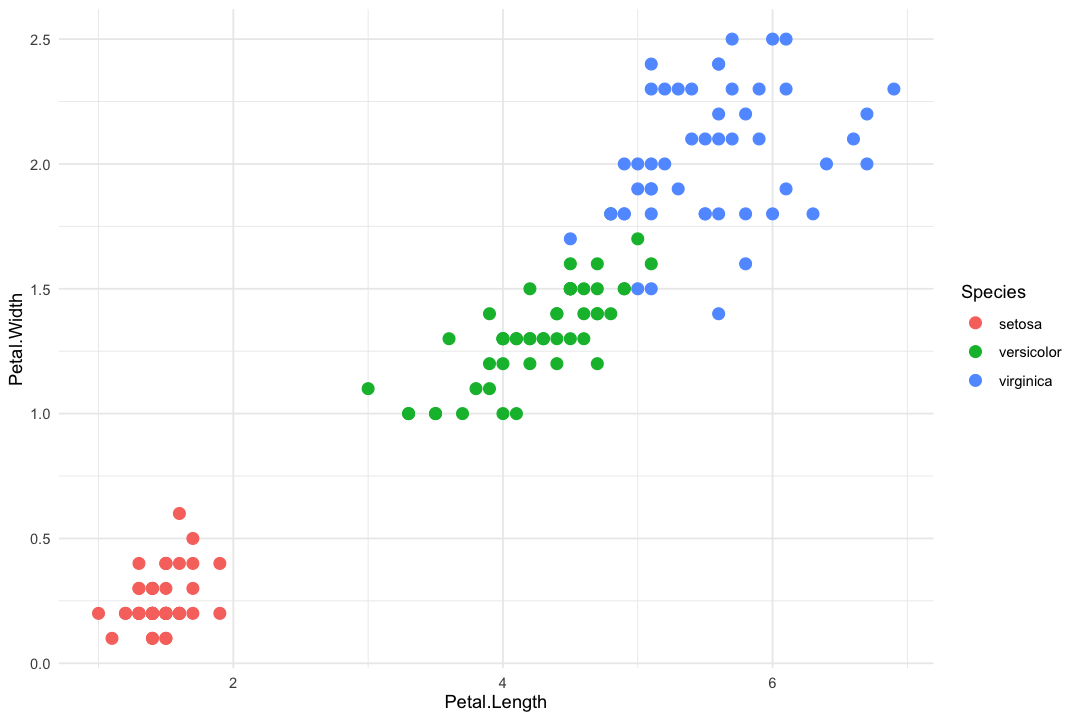

In [5]:
ggplot(iris, aes(x = Petal.Length, y = Petal.Width, color = Species)) +
  geom_point(size = 3) +
  theme_minimal()

init
 1  2  3 
44 51 55 

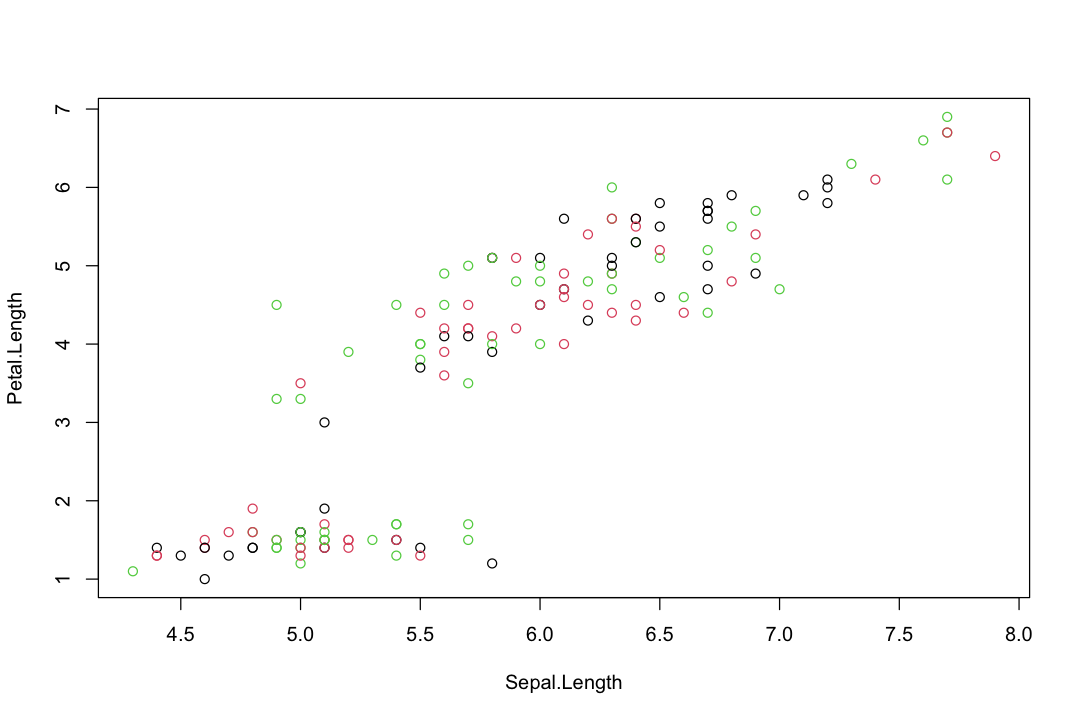

In [6]:
clusters <- 3   # 3 clusters, matching the 3 species

# assign each point randomly to a cluster
init <- sample(clusters, nrow(x), replace = TRUE)
table(init)

plot(x, col = init)

Sepal.Length,Petal.Length
5.925000,3.906818
5.762745,3.607843
5.852727,3.778182


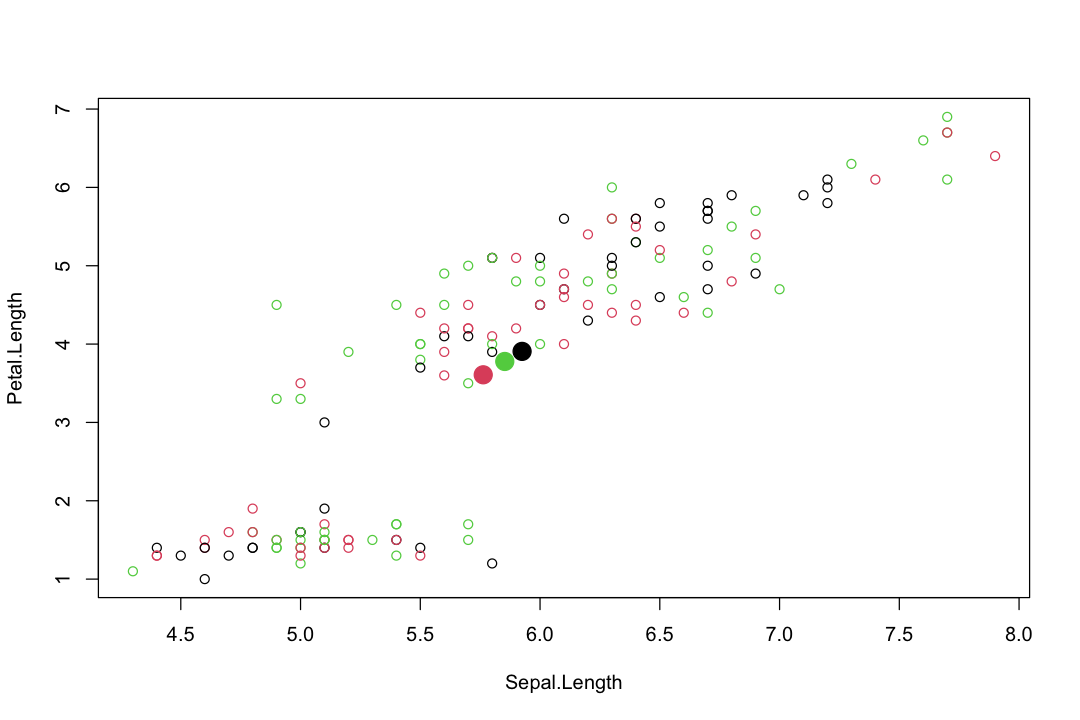

In [7]:
centres <- sapply(1:clusters, function(i) colMeans(x[init == i, ]))
centres <- t(centres)
centres

plot(x, col = init)
points(centres[, 1], centres[, 2], pch = 19, col = 1:clusters, cex = 2)

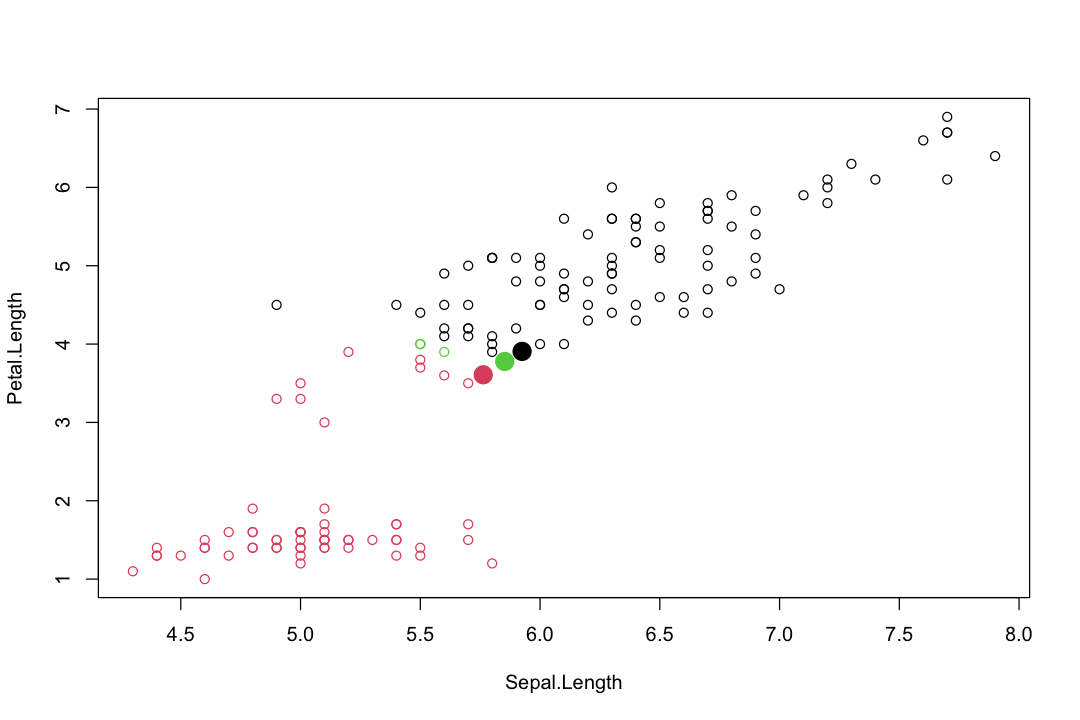

In [8]:
tmp <- dist(rbind(centres, x))
tmp <- as.matrix(tmp)[, 1:clusters]
ki  <- apply(tmp, 1, which.min)
ki  <- ki[-(1:clusters)]   # drop the rows for the centres, then plot

plot(x, col = ki)
points(centres[, 1], centres[, 2], pch = 19, col = 1:clusters, cex = 2)

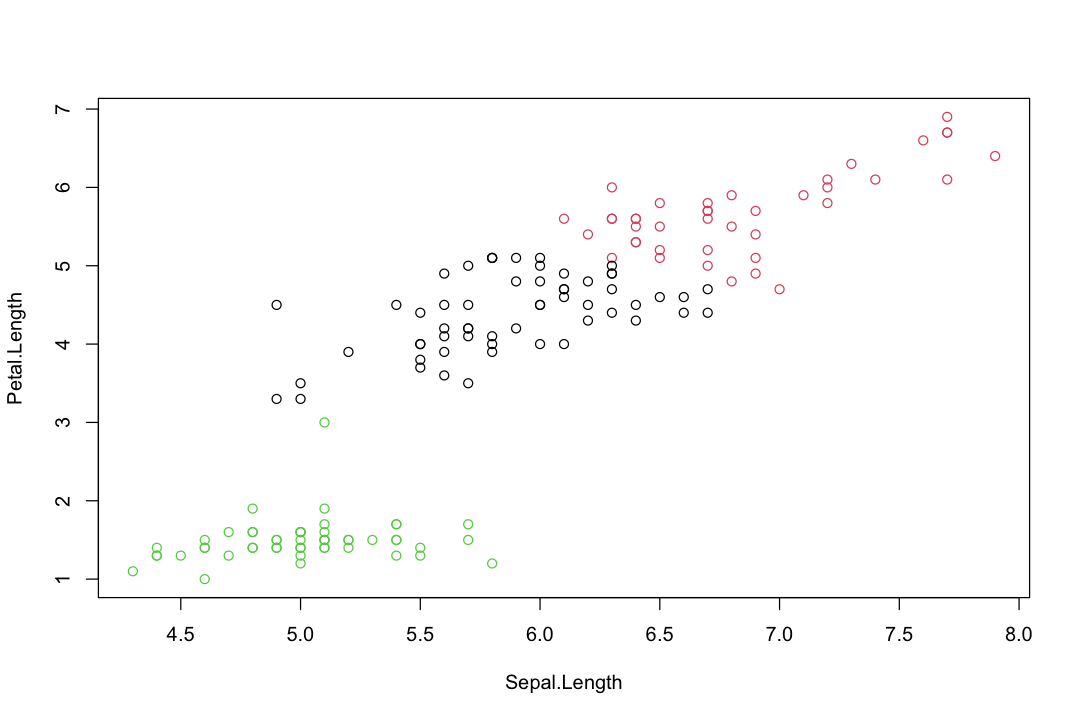

In [9]:
cl <- kmeans(x, clusters, nstart = 10)   # run the model with 3 clusters
plot(x, col = cl$cluster)

In [10]:
# Cluster numbers are arbitrary, so match each cluster to the
# species that appears most often inside it.
conf <- table(Cluster = cl$cluster, Species = iris$Species)
conf

cluster_to_species <- apply(conf, 1, function(r) colnames(conf)[which.max(r)])
predicted <- cluster_to_species[as.character(cl$cluster)]

accuracy <- mean(predicted == as.character(iris$Species))
accuracy

       Species
Cluster setosa versicolor virginica
      1      0         45        13
      2      0          4        37
      3     50          1         0

[1] 0.88

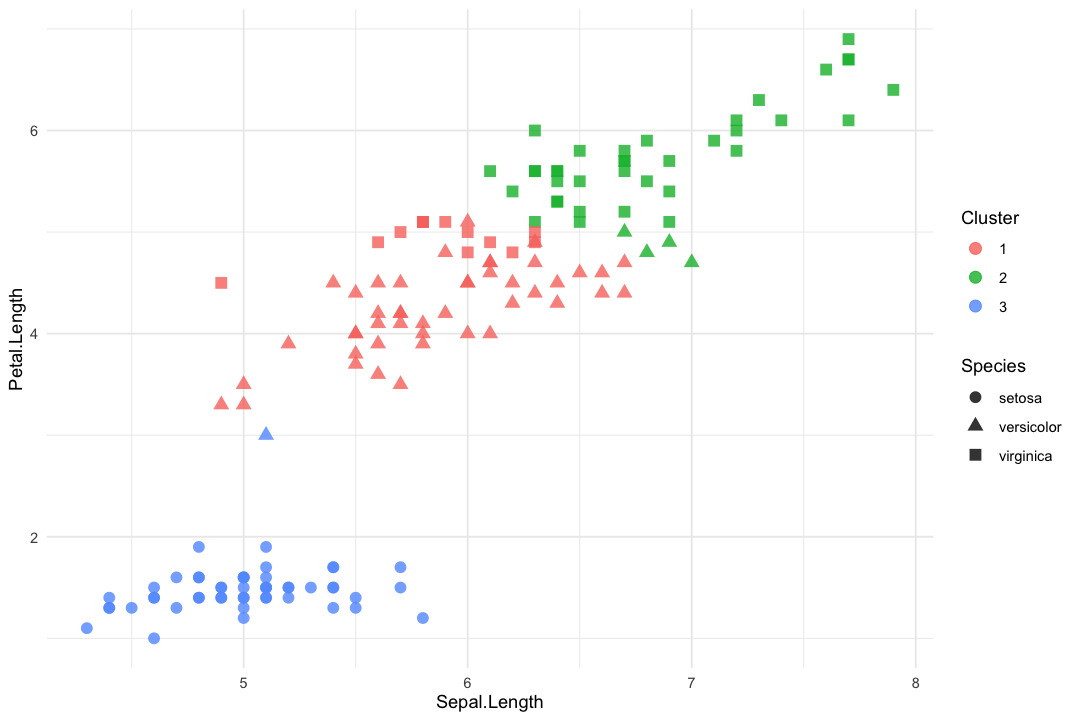

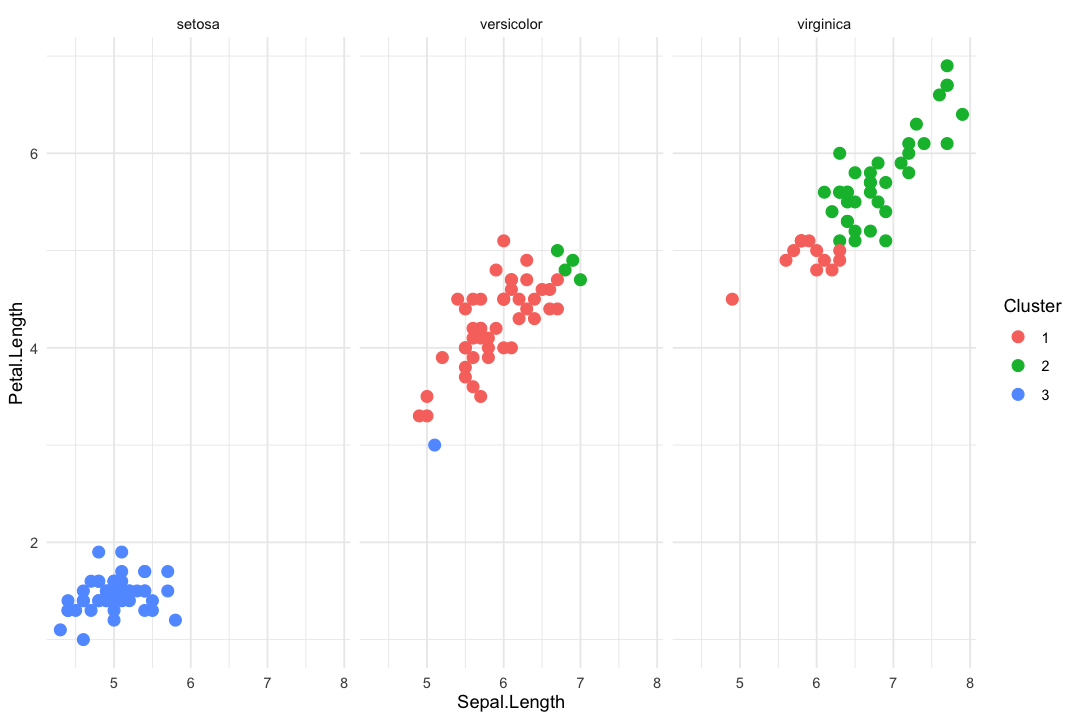

In [11]:
plot_df <- data.frame(x, Species = iris$Species, Cluster = factor(cl$cluster))

# color = kMeans cluster, shape = biologists' species
ggplot(plot_df, aes(x = Sepal.Length, y = Petal.Length,
                    color = Cluster, shape = Species)) +
  geom_point(size = 3, alpha = 0.8) +
  theme_minimal()

# clusters within each species
ggplot(plot_df, aes(x = Sepal.Length, y = Petal.Length, color = Cluster)) +
  geom_point(size = 3) +
  facet_wrap(~ Species) +
  theme_minimal()

k,tot_withinss
<int>,<dbl>
1,566.49373
2,112.99207
3,53.80998
4,34.31702
5,25.63406
6,21.80263


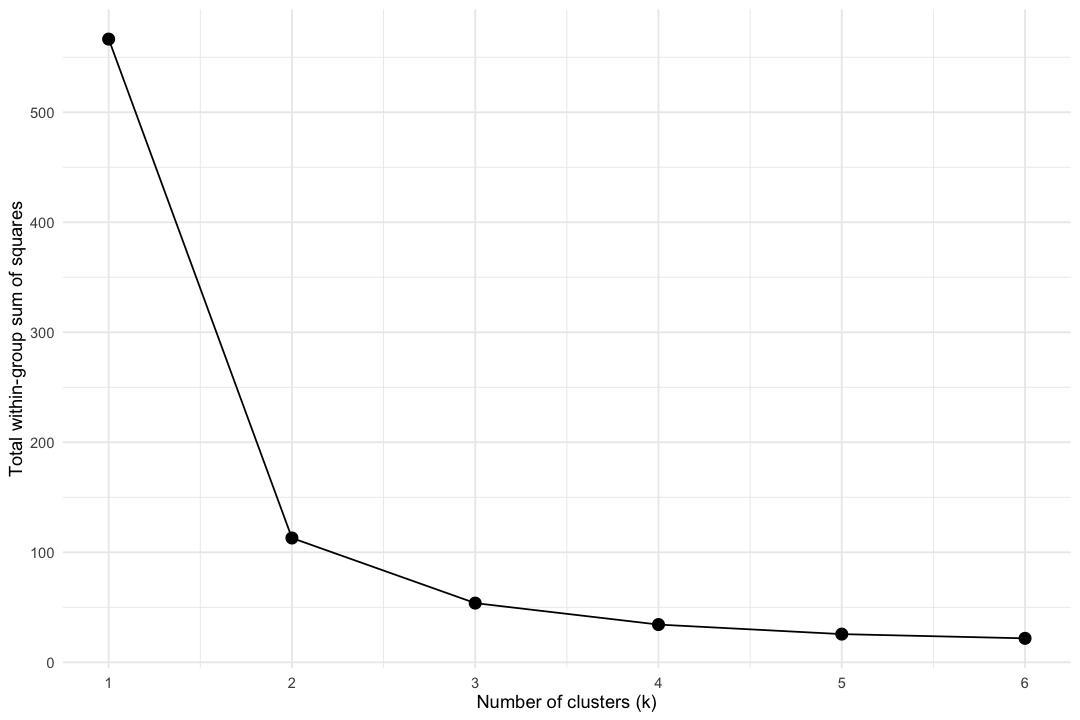

In [12]:
ks <- 1:6
tot_within_ss <- sapply(ks, function(k) {
  kmeans(x, k, nstart = 10)$tot.withinss
})

elbow_df <- data.frame(k = ks, tot_withinss = tot_within_ss)
elbow_df

ggplot(elbow_df, aes(x = k, y = tot_withinss)) +
  geom_line() +
  geom_point(size = 3) +
  scale_x_continuous(breaks = ks) +
  labs(x = "Number of clusters (k)",
       y = "Total within-group sum of squares") +
  theme_minimal()